# Task 3

## Task 3.1

In [10]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

### Data generation class

In [11]:
class NoisyXOR(Dataset):
    """Noisy-XOR data: 4 clusters at (0,0),(0,1),(1,0),(1,1) with Gaussian noise of std s."""
    def __init__(self, n_samples=1000, s=0.1, seed=None):
        g = torch.Generator()
        if seed is not None:
            g.manual_seed(seed)
        # pick a random cluster center (m1, m2) in {0,1}^2 for each sample (equal probability)
        m = torch.randint(0, 2, (n_samples, 2), generator=g).float()
        # add noise: x = m + s * eta, with eta ~ N(0,1)
        self.x = m + s * torch.randn(n_samples, 2, generator=g)
        # label = m1 XOR m2 (1 if the two coordinates differ)
        self.y = (m[:, 0] != m[:, 1]).float().unsqueeze(1)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        return self.x[i], self.y[i]

### Model class

In [12]:
class Net(nn.Module):
    """Feed-forward net. Default = the network in Figure 2 (1 hidden layer, 3 units)."""
    def __init__(self, n_hidden_layers=1, width=3):
        super().__init__()
        layers = []
        in_features = 2
        for _ in range(n_hidden_layers):
            layers += [nn.Linear(in_features, width), nn.Tanh()]  # hidden layer + tanh
            in_features = width
        layers += [nn.Linear(in_features, 1), nn.Identity()]      # output = raw logit
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

### Training loop

In [13]:
def train(model, train_loader, val_loader, epochs=100, lr=0.01):
    loss_fn = nn.BCEWithLogitsLoss()                     # sigmoid is built into the loss
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        # --- training: one pass over mini-batches ---
        model.train()
        total = 0
        for x, y in train_loader:
            optimizer.zero_grad()            # reset gradients
            loss = loss_fn(model(x), y)      # forward pass + loss
            loss.backward()                  # backpropagation
            optimizer.step()                 # Adam update
            total += loss.item() * len(x)
        train_losses.append(total / len(train_loader.dataset))

        # --- validation: no gradients needed ---
        model.eval()
        total = 0
        with torch.no_grad():
            for x, y in val_loader:
                total += loss_fn(model(x), y).item() * len(x)
        val_losses.append(total / len(val_loader.dataset))

    return train_losses, val_losses

### Plotting like Figure 1

In [14]:
def plot_data(dataset, title):
    x, y = dataset.x, dataset.y.squeeze()
    plt.scatter(x[y == 0, 0], x[y == 0, 1], label="Class 0", edgecolor="k")
    plt.scatter(x[y == 1, 0], x[y == 1, 1], label="Class 1", edgecolor="k")
    plt.xlabel("x1"); plt.ylabel("x2"); plt.title(title); plt.legend()
    plt.gca().set_aspect("equal")

### Run it

Net(
  (model): Sequential(
    (0): Linear(in_features=2, out_features=3, bias=True)
    (1): Tanh()
    (2): Linear(in_features=3, out_features=1, bias=True)
    (3): Identity()
  )
)


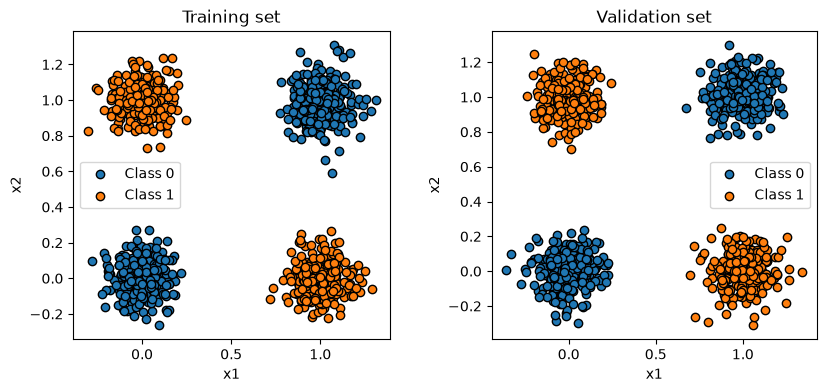

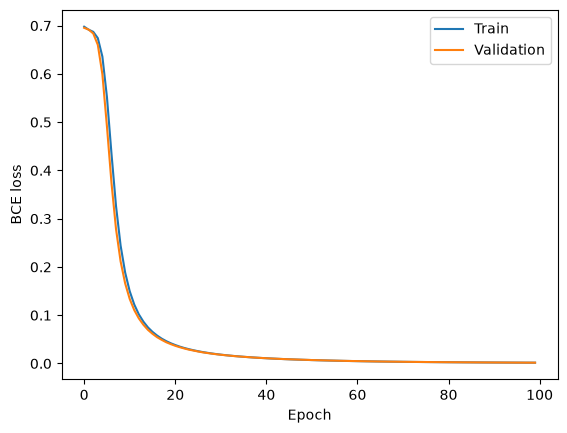

In [15]:
train_set = NoisyXOR(n_samples=1000, s=0.1, seed=0)
val_set   = NoisyXOR(n_samples=1000, s=0.1, seed=1)   # different seed = new data
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_set, batch_size=32)

model = Net(n_hidden_layers=1, width=3)
print(model)
train_losses, val_losses = train(model, train_loader, val_loader, epochs=100, lr=0.01)

# data plots for training and validation set
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plot_data(train_set, "Training set")
plt.subplot(1, 2, 2); plot_data(val_set, "Validation set")
plt.show()

# loss curves
plt.plot(train_losses, label="Train"); plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch"); plt.ylabel("BCE loss"); plt.legend(); plt.show()

## Task 3.2

### Evaluation helper

In [16]:
def evaluate(model, loader):
    """Mean BCE loss of a trained model on a data set."""
    loss_fn = nn.BCEWithLogitsLoss()
    model.eval()
    total = 0
    with torch.no_grad():
        for x, y in loader:
            total += loss_fn(model(x), y).item() * len(x)
    return total / len(loader.dataset)

### Run the experiment

In [17]:
import numpy as np

n_repeats = 10                                   # repetitions per (depth, width) combination
depths = [0, 1, 2, 3]                            # number of hidden layers
widths = [1, 2, 3]                               # units per hidden layer
results = {}                                     # (depth, width) -> (mean loss, std loss)

for depth in depths:
    # with 0 hidden layers the width has no meaning (the model is just a linear classifier),
    # so we only run that case once
    for width in (widths if depth > 0 else [1]):
        test_losses = []
        for r in range(n_repeats):
            # new training data, new test data and new random weights in every repetition
            train_set = NoisyXOR(n_samples=1000, s=0.1, seed=2 * r)
            test_set  = NoisyXOR(n_samples=1000, s=0.1, seed=2 * r + 1)
            train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
            test_loader  = DataLoader(test_set, batch_size=32)

            model = Net(n_hidden_layers=depth, width=width)
            train(model, train_loader, test_loader, epochs=100, lr=0.01)
            test_losses.append(evaluate(model, test_loader))   # loss on the new data set

        results[(depth, width)] = (np.mean(test_losses), np.std(test_losses))
        print(f"depth={depth} width={width}: "
              f"mean loss={results[(depth, width)][0]:.4f}, std={results[(depth, width)][1]:.4f}")

depth=0 width=1: mean loss=0.6938, std=0.0013
depth=1 width=1: mean loss=0.4822, std=0.0120
depth=1 width=2: mean loss=0.1422, std=0.1692
depth=1 width=3: mean loss=0.0023, std=0.0009
depth=2 width=1: mean loss=0.4797, std=0.0087
depth=2 width=2: mean loss=0.1214, std=0.1855
depth=2 width=3: mean loss=0.0336, std=0.0984
depth=3 width=1: mean loss=0.4764, std=0.0104
depth=3 width=2: mean loss=0.2155, std=0.2172
depth=3 width=3: mean loss=0.0016, std=0.0027


### Summary table

In [18]:
print(f"{'Hidden layers':>13} {'Width':>6} {'Mean loss':>10} {'Std':>8}")
for (depth, width), (mean, std) in results.items():
    print(f"{depth:>13} {(width if depth > 0 else '-'):>6} {mean:>10.4f} {std:>8.4f}")

Hidden layers  Width  Mean loss      Std
            0      -     0.6938   0.0013
            1      1     0.4822   0.0120
            1      2     0.1422   0.1692
            1      3     0.0023   0.0009
            2      1     0.4797   0.0087
            2      2     0.1214   0.1855
            2      3     0.0336   0.0984
            3      1     0.4764   0.0104
            3      2     0.2155   0.2172
            3      3     0.0016   0.0027


## Task 3.3

### Parameter counts

In [19]:
# Count the trainable parameters (weights + biases) of every tested network
print(f"{'Hidden layers':>13} {'Width':>6} {'Parameters':>11}")
for (depth, width) in results.keys():
    model = Net(n_hidden_layers=depth, width=width)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{depth:>13} {(width if depth > 0 else '-'):>6} {n_params:>11}")

Hidden layers  Width  Parameters
            0      -           3
            1      1           5
            1      2           9
            1      3          13
            2      1           7
            2      2          15
            2      3          25
            3      1           9
            3      2          21
            3      3          37


## Task 3.4

### Train the minimal network and save the weights during training

In [20]:
import copy
import numpy as np
from matplotlib.animation import FuncAnimation, PillowWriter

torch.manual_seed(0)
train_set = NoisyXOR(n_samples=1000, s=0.1, seed=0)
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)

model = Net(n_hidden_layers=1, width=2)       # minimal XOR network: 2 hidden units, tanh
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 60
snapshots = [copy.deepcopy(model.state_dict())]    # weights before training (epoch 0)

for epoch in range(epochs):
    for x, y in train_loader:
        optimizer.zero_grad()
        loss_fn(model(x), y).backward()
        optimizer.step()
    snapshots.append(copy.deepcopy(model.state_dict()))   # save weights after every epoch

with torch.no_grad():
    print("Final training loss:", loss_fn(model(train_set.x), train_set.y).item())

Final training loss: 0.010378941893577576


### Function that draws the three decision boundaries for one saved epoch

In [21]:
# Grid of points covering the input space
xx, yy = np.meshgrid(np.linspace(-0.25, 1.25, 150), np.linspace(-0.25, 1.25, 150))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

x_np = train_set.x.numpy()
y_np = train_set.y.squeeze().numpy()
titles = ["Hidden 1", "Hidden 2", "Output"]

def draw_epoch(axes, epoch):
    """Draw the 3 decision regions of the network with the weights saved at `epoch`."""
    model.load_state_dict(snapshots[epoch])
    with torch.no_grad():
        h = torch.tanh(model.model[0](grid))              # hidden activations
        p = torch.sigmoid(model.model[2](h))              # output probability p(y=1)
    # a hidden unit is "on" when tanh > 0, the output unit when p > 0.5
    regions = [h[:, 0] > 0, h[:, 1] > 0, p[:, 0] > 0.5]

    for ax, region, title in zip(axes, regions, titles):
        ax.clear()
        Z = region.numpy().reshape(xx.shape).astype(float)
        ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], alpha=0.3,
                    colors=["#ffcccc", "#ccffcc"])        # red = class 0 side, green = class 1 side
        ax.scatter(x_np[y_np == 0, 0], x_np[y_np == 0, 1], c="red", s=8)
        ax.scatter(x_np[y_np == 1, 0], x_np[y_np == 1, 1], c="green", s=8)
        ax.set_title(f"{title} (epoch {epoch})")
        ax.set_xlim(-0.25, 1.25); ax.set_ylim(-0.25, 1.25)
        ax.set_xlabel("x1"); ax.set_ylabel("x2")

### Make the movie

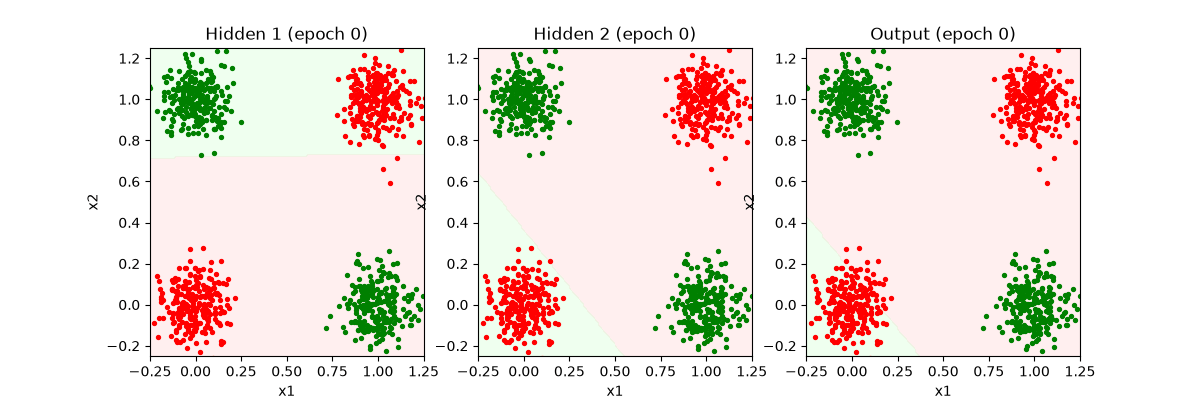

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
anim = FuncAnimation(fig, lambda f: draw_epoch(axes, f), frames=len(snapshots), interval=150)
anim.save("xor_training.gif", writer=PillowWriter(fps=6))   # gif needs no extra software
plt.close(fig)

# show the movie in the notebook
from IPython.display import Image
Image("xor_training.gif")

### Snapshots for the report

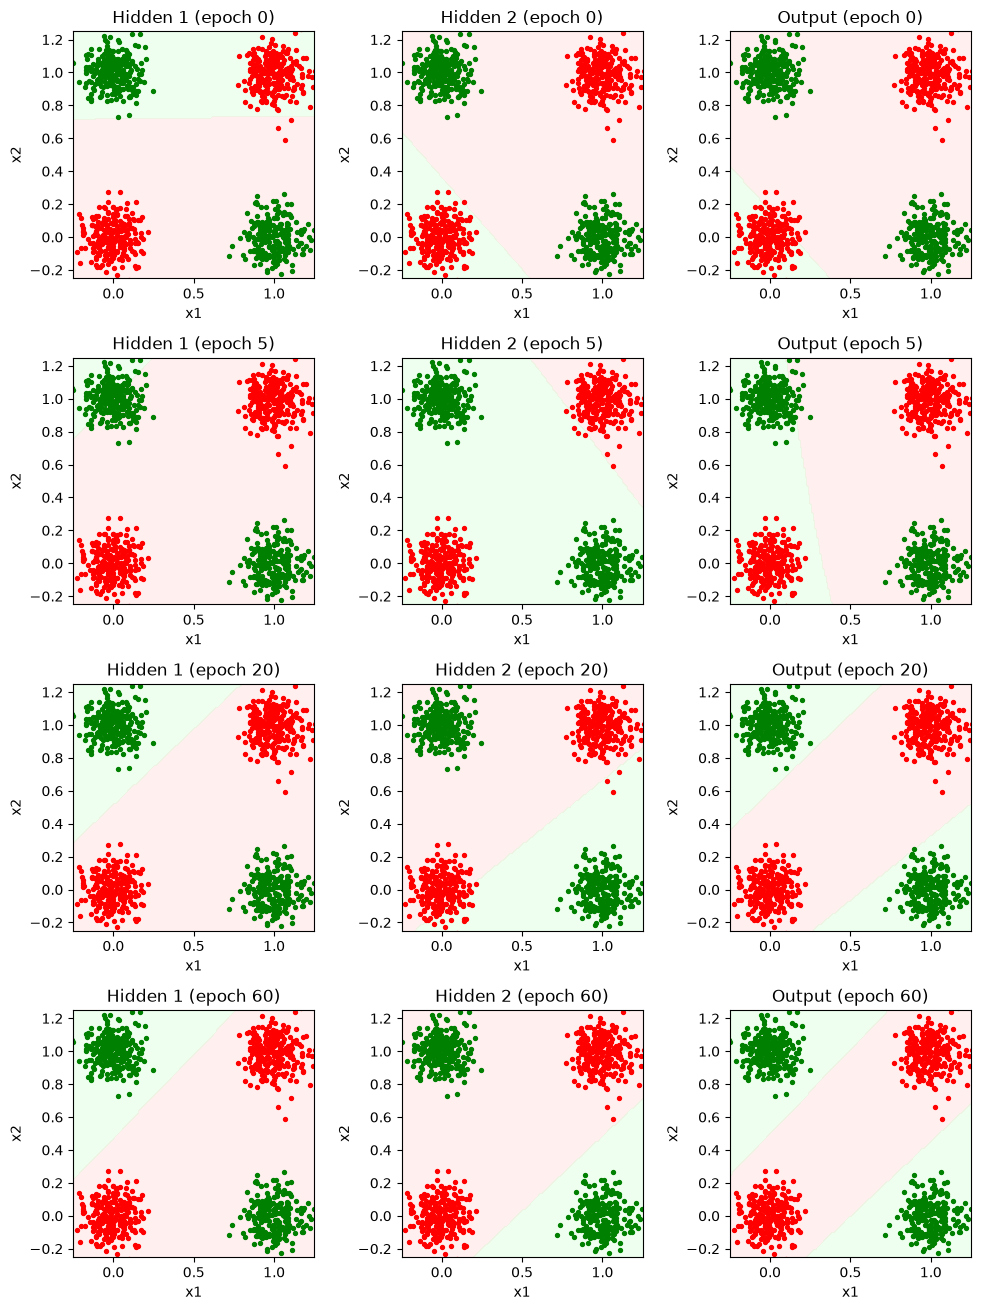

In [23]:
snapshot_epochs = [0, 5, 20, 60]
fig, axes = plt.subplots(len(snapshot_epochs), 3, figsize=(10, 3.3 * len(snapshot_epochs)))
for row, e in zip(axes, snapshot_epochs):
    draw_epoch(row, e)
plt.tight_layout()
plt.savefig("xor_snapshots.png", dpi=150)
plt.show()